# Task 1: a model that predicts what a signup is worth

**How to read this.** Text cells explain what we do and why, in plain language. Code cells do it. The table or chart under a code cell is its result. You do not need to read the code to follow the story.

**The question.** Meta and Google Ads optimise for signups. Some signups never connect a phone number, others pay for months. We want to tell the platforms, 72 hours after each signup, how much that signup is probably worth in euros.

**The answer.** We built one model for Meta signups and one for Google Ads signups. We tested them on February and March 2026, two months they were not trained on. The 30% of signups with the highest predicted value brought **85% of Meta's revenue** and **74% of Google Ads' revenue**. Without a model, every signup counts the same, and 30% of signups bring 30% of revenue.

Sections follow the task: **1 Build the model · 2 When we score · 3 Which features we use · 4 How we validated it · 5 Other checks · 6 Decisions.**

*Tooling: Python 3.11, pandas, scikit-learn, matplotlib, Jupyter. Claude Code was used as a pair programmer and sparring partner; decisions and text are mine.*

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
import numpy as np, pandas as pd
from IPython.display import Image, display
from src.features import load, feature_frame, split_by_time, channel_mask, EXCLUDED
from src.model import LeadValueModel
from src import evaluate as ev
pd.set_option("display.width", 140); pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
df = load("../data/fonio_case_signups.csv")
print(f"{len(df):,} signups from {df.signup_date.min().date()} to {df.signup_date.max().date()}")

6,000 signups from 2025-10-01 to 2026-03-31


## 0. What the data looks like

One row per signup. For each signup we know what the person told us in the form (country, industry, company size), what the browser told us (device, channel), what they did in the product in the first days (phone connected, assistant set up, test calls, calendar), and what happened afterwards (did they pay within 30 days, how much they paid over 180 days).

In [2]:
by_channel = df.groupby("channel").agg(signups=("signup_id","size"), share_of_signups=("signup_id", lambda s: len(s)/len(df)),
    paid_within_30d=("converted_paid_30d","mean"), revenue_180d_per_signup=("revenue_180d_eur","mean")).sort_values("signups", ascending=False)
by_channel.style.format({"share_of_signups": "{:.0%}", "paid_within_30d": "{:.0%}", "revenue_180d_per_signup": "€{:.0f}"})

,signups,share_of_signups,paid_within_30d,revenue_180d_per_signup
channel,,,,
meta,2555,43%,16%,€101
google_search,1519,25%,38%,€326
google_pmax,773,13%,26%,€181
organic,703,12%,31%,€242
referral,450,8%,34%,€298


Meta brings 43% of all signups, but a Meta signup is worth about €101 over 180 days, against €326 for a Google Search signup. Only 16% of Meta signups pay. The job of the model is to find those 16% early.

**What "revenue over 180 days" is.** In this dataset it is exactly *plan price × number of months the customer stayed* (1 to 6 months). So it already rewards customers who stay: a cheap plan kept for 6 months is worth more than an expensive plan dropped after one month. The three plans in the dataset cost €49, €99 and €249 per month (synthetic prices; production would use the real Solo/Team/Scale prices).

In [3]:
payers = df[df.converted_paid_30d == 1]
payers.groupby("plan_selected").revenue_180d_eur.agg(["min", "max", "mean"]).rename(columns={"min": "1 month", "max": "6 months", "mean": "average"}).style.format("€{:.0f}")

,1 month,6 months,average
plan_selected,,,
business,€249,€1494,€1133
pro,€99,€594,€400
starter,€49,€294,€191


## 1. Build the model

### Which signups go into which model

We only ever send values to two places: Meta and Google Ads. So we build **two models**:

| Model | Trained and used on | Signups |
|---|---|---|
| Meta model | channel = `meta` | 2,555 |
| Google Ads model | channel = `google_search` + `google_pmax` (two campaign types of the same Google Ads account, bidding on the same conversion action) | 2,292 |

**Organic and referral signups are not used at all**, neither for training nor for scoring. There is no ad platform to send their value to, and their behaviour differs from paid traffic. Section 5 shows that mixing all channels into one model does not help.

### How the model works, in plain words

A model is a formula. It takes the facts we know about a signup 72 hours in and turns them into one number: expected revenue in euros.

**Training** is how the formula gets its numbers. We give the computer the signups from October to January as a *worked answer key*: for each one, the facts at 72h **and** the outcome (`converted_paid_30d` and `revenue_180d_eur`). Those two outcome columns are only used as the answers to learn from. They are never used as inputs, because in real life they do not exist yet when we score.

**Two steps.** 74% of signups bring €0 (only 26% ever pay), so one formula for the euro amount would mostly be guessing zeros. We split the question:

1. **Will this signup pay within 30 days?** A *logistic regression*: every fact gets a weight (phone connected: +0.82, solo company: −0.21, ...), the weights are added up, and the sum is turned into a probability between 0 and 1. The computer finds the weights by trying values, checking how many of the training signups it gets right, and adjusting, thousands of times, until the error stops shrinking.
2. **If they pay, how much over 180 days?** A second formula with its own weights, trained **only on the training signups that did pay** (we know which ones from the answer key). It learns which traits go with bigger, longer-lasting plans.

**Value = (chance of paying) × (revenue if they pay).** A signup with a 55% chance of paying and €900 expected if they pay is worth €495. A signup with a 3% chance and €400 is worth €12.

**Testing** uses the signups from February and March, which were *not* shown to the computer during training. We let the formula predict them and compare with what really happened.

In [4]:
# Train one model per platform on Oct 2025 - Jan 2026. Keep Feb - Mar 2026 aside for testing.
X72 = feature_frame(df, "72h")                      # the facts known 72 hours after signup
y_paid, y_rev = df.converted_paid_30d.values, df.revenue_180d_eur.values   # the answer key
train, test = split_by_time(df)                     # before / from 1 Feb 2026
models, scores, test_mask = {}, {}, {}
for platform in ["meta", "google"]:
    tr, te = train & channel_mask(df, platform), test & channel_mask(df, platform)
    models[platform] = LeadValueModel("logreg", "ridge").fit(X72[tr], y_paid[tr], y_rev[tr])
    scores[platform], test_mask[platform] = models[platform].predict_value(X72[te]), te
    print(f"{platform:7s} trained on {tr.sum():,} signups ({int(y_paid[tr].sum())} of them paid); kept {te.sum():,} Feb-Mar signups for testing")

meta    trained on 1,753 signups (282 of them paid); kept 802 Feb-Mar signups for testing
google  trained on 1,534 signups (510 of them paid); kept 758 Feb-Mar signups for testing


### Three real signups from the test months, scored by the Meta model

`p_pay` is step 1, `revenue_if_pays` is step 2, `value` is what we would send to Meta. The last two columns show what really happened; single signups always vary, the test of the model is whether groups of signups average out (section 4). None of the three had paid by 72h, so the model judged them on behaviour alone.

In [5]:
R = json.load(open("../outputs/results.json"))
cols = ["industry","company_size","device","business_email","phone_connected_24h","assistant_configured_24h","test_calls_72h","calendar_connected_72h","p_pay","revenue_if_pays","value","converted_paid_30d","revenue_180d_eur"]
pd.DataFrame(R["tables"]["examples_meta"]).set_index("label")[cols].T

label,high,median,low
industry,trades,other,automotive
company_size,6-20,1,1
device,desktop,mobile,mobile
business_email,1,0,0
phone_connected_24h,1,1,0
assistant_configured_24h,1,0,1
test_calls_72h,9,0,0
calendar_connected_72h,0,0,0
p_pay,0.93,0.05,0.00
revenue_if_pays,865.00,409.00,136.00


## 2. When we score: 24 hours or 72 hours?

The earlier we score, the sooner the platform gets the signal, but the less we know:

| Scoring moment | What we know by then |
|---|---|
| at signup | form + browser only |
| **24 h** | + phone connected, assistant configured |
| **72 h** | + test calls, calendar connected, and whether they already paid |

Both moments fit the platforms' windows (Meta Conversions API accepts events up to 7 days old; Google Ads accepts conversions inside the action's window, which we set to 30 days). The question is how much accuracy we gain by waiting.

In [6]:
rows = []
for platform in ["meta","google"]:
    for h in ["24h","72h"]:
        X = feature_frame(df, h); tr, te = train & channel_mask(df, platform), test & channel_mask(df, platform)
        s = LeadValueModel().fit(X[tr], y_paid[tr], y_rev[tr]).predict_value(X[te])
        r = ev.summary(s, y_paid[te], y_rev[te]); rows.append({"platform": platform, "scored at": h, "revenue in the top 30% of signups": r["revenue_top30_share"]})
pd.DataFrame(rows).pivot(index="platform", columns="scored at", values="revenue in the top 30% of signups").style.format("{:.0%}")

scored at,24h,72h
platform,,
google,65%,74%
meta,81%,85%


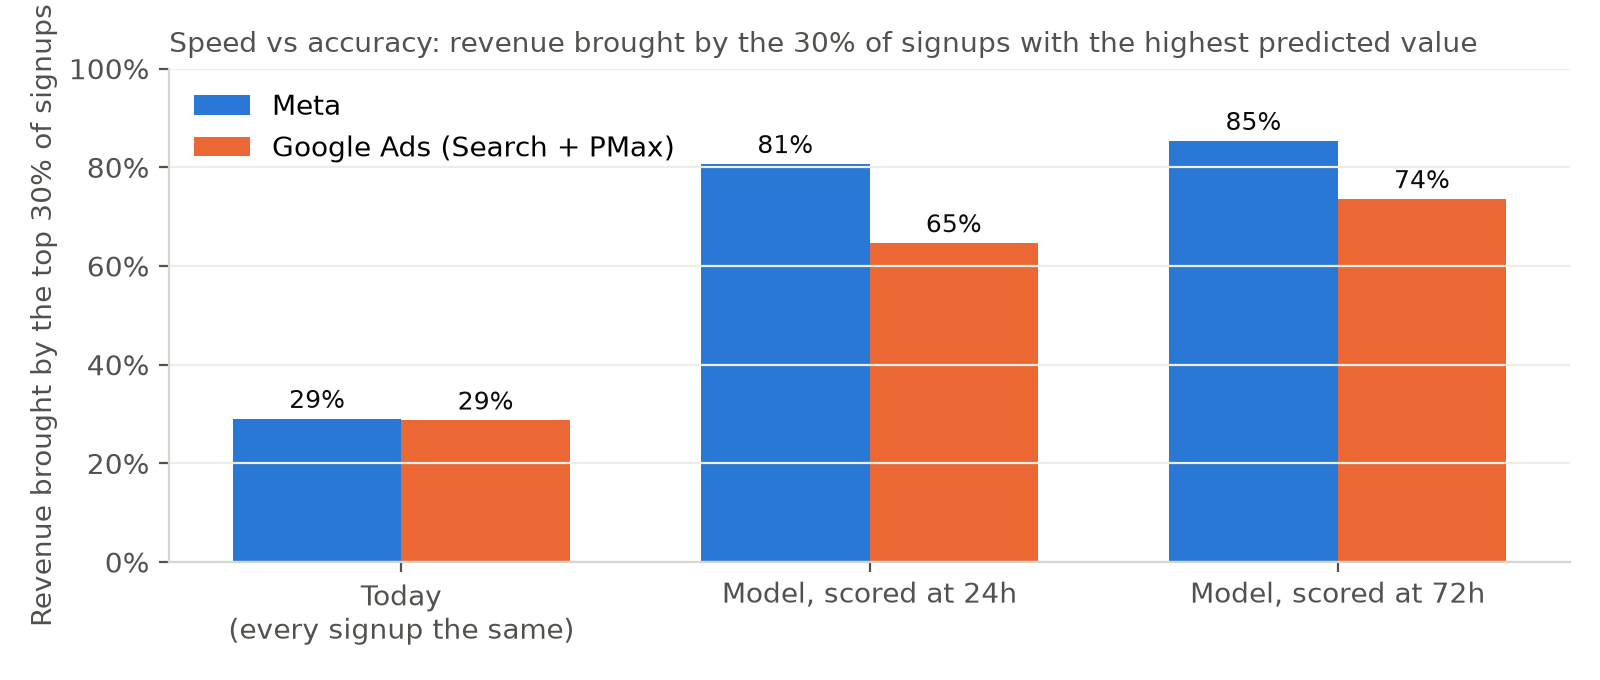

In [7]:
display(Image("../outputs/figures/horizon_tradeoff.png", width=720))

**Decision: score at 72 hours.** Waiting two more days adds 4 points on Meta and 9 points on Google.

## 3. Which features we use, and which we leave out

**Used, exactly as the columns are named in the table:** `country`, `industry`, `company_size`, `device`, `business_email`, `signup_hour`, `signup_date` (as weekday), `phone_connected_24h`, `assistant_configured_24h`, `test_calls_72h`, `calendar_connected_72h`.

**Plus two features of our own:** `paid_by_72h` = True if `days_to_first_payment` ≤ 3, otherwise False; `plan_by_72h` = `plan_selected` for those signups, `none` for everyone else. In the data every payer has a plan and every plan has a payment, so the two always match. 152 of the 1,559 payers had already paid by 72h.

**Left out, and why:**

In [8]:
pd.Series(EXCLUDED, name="why it is left out").to_frame()

,why it is left out
plan_selected,outcome of the payment; at 72h it is 'none' fo...
days_to_first_payment,outcome; only used to derive 'paid_by_h'
converted_paid_30d,target
revenue_180d_eur,target
minutes_used_7d,needs 7 days; not available at 72h
onboarding_call_booked,no timestamp in the dataset; cannot be placed ...
signup_id,identifier


**Why `plan_selected` and `days_to_first_payment` are left out.** They are filled in when the payment happens, and at 72 hours only 3% of signups have paid. In production the model would see `none` and an empty date for 97% of new signups and would rate almost all of them as worthless. We use these two columns only to build `paid_by_72h` and `plan_by_72h`. The table below shows why they look so tempting in the file: plan and payment match row for row.

In [9]:
print(pd.crosstab(df.plan_selected, df.converted_paid_30d.map({0: "did not pay", 1: "paid"})))
d = df.days_to_first_payment
print(f"\npayers: {int(df.converted_paid_30d.sum())}  |  already paid by 24h: {int(d.le(1).sum())}  |  by 72h: {int(d.le(3).sum())}  |  by day 7: {int(d.le(7).sum())}")

converted_paid_30d  did not pay  paid
plan_selected                        
business                      0   844
none                       4441     0
pro                           0   498
starter                       0   217

payers: 1559  |  already paid by 24h: 58  |  by 72h: 152  |  by day 7: 359


## 4. How we validated it, and how much better it is than treating every signup the same

The file holds six months of signups with known outcomes. We built the models on the first four months (October 2025 to January 2026) and kept the last two (February and March 2026) aside. The split follows time, as in production: the model learns from the past and is applied to what comes next. Four months give enough examples to learn from (280 Meta payers), two months give enough to judge (802 Meta signups). The models then predicted a value for every February-March signup, and we compared it with the real `converted_paid_30d` and `revenue_180d_eur`.

**What "treating every signup the same" means.** That is today's setup: every signup is worth the same to the platform. If you pick any 30% of signups, you get, on average, 30% of the revenue.

### 4a. Revenue brought by the 30% of signups with the highest predicted value

Rank the test signups by predicted value, take the top 30%, add up the revenue they really brought, divide by the revenue of all test signups.

*A small example:* ten signups whose real revenue is € 500, € 300, € 150, € 50 and six times € 0, € 1,000 in total. Any three picked at random bring about € 300 (30%). If the model's top three are the € 500, € 300 and € 150 signups, they bring € 950 (95%). The closer to 100%, the better the model sorts the money to the top.

In [10]:
rows = []
for platform in ["meta","google"]:
    te = test_mask[platform]
    random_order = np.random.default_rng(0).random(te.sum())   # "today": no ranking, any order is as good as any other
    for name, s in [("today: every signup the same", random_order), ("lead-value model (72h)", scores[platform])]:
        r = ev.summary(s, y_paid[te], y_rev[te])
        rows.append({"platform": platform, "scoring": name, "test signups": r["n"], "revenue in top 30%": r["revenue_top30_share"], "revenue in top 50%": r["revenue_top50_share"]})
pd.DataFrame(rows).set_index(["platform","scoring"]).style.format({"revenue in top 30%": "{:.0%}", "revenue in top 50%": "{:.0%}"})

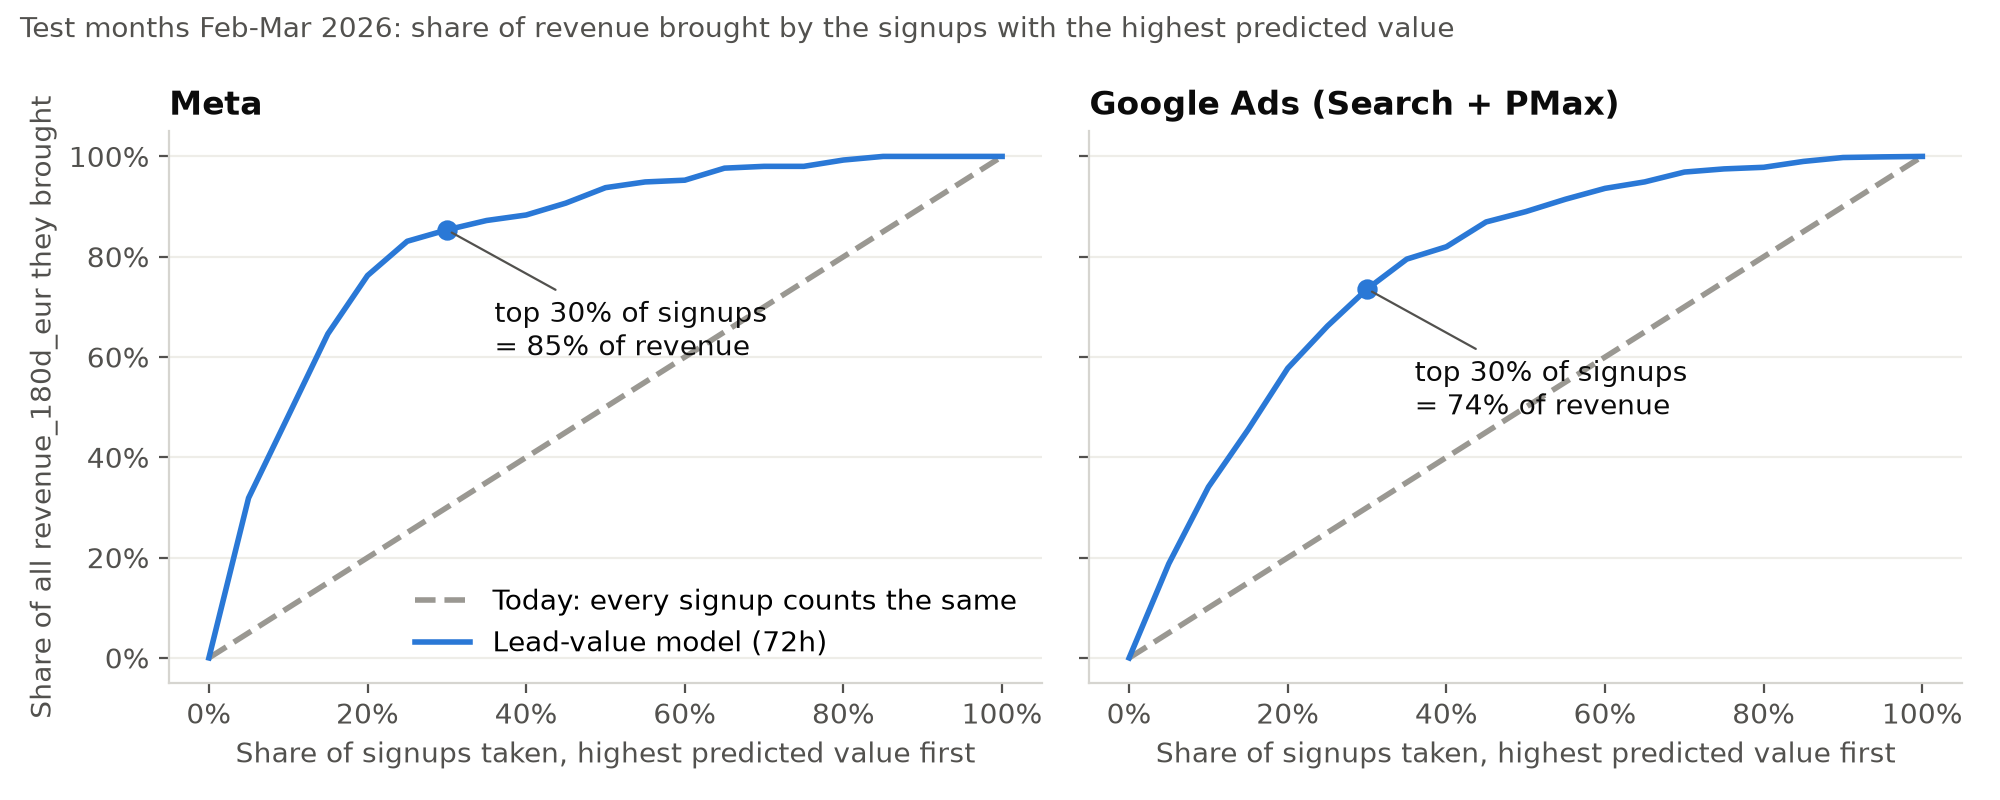

In [11]:
display(Image("../outputs/figures/gain_curves.png", width=900))

The chart shows the same thing for every cut-off, not only 30%. The dashed diagonal is today. The blue line is the model.

### 4b. Split the test signups into thirds by predicted value

If the model works, the top third should pay far more often and bring far more money than the bottom third.

--- meta ---


,signups,paid within 30d,real revenue per signup,model's predicted value
tertile,,,,
top,267,39%,€270,€247
middle,267,9%,€33,€28
bottom,268,2%,€7,€5


--- google ---


,signups,paid within 30d,real revenue per signup,model's predicted value
tertile,,,,
top,253,73%,€666,€650
middle,252,25%,€159,€167
bottom,253,8%,€42,€28


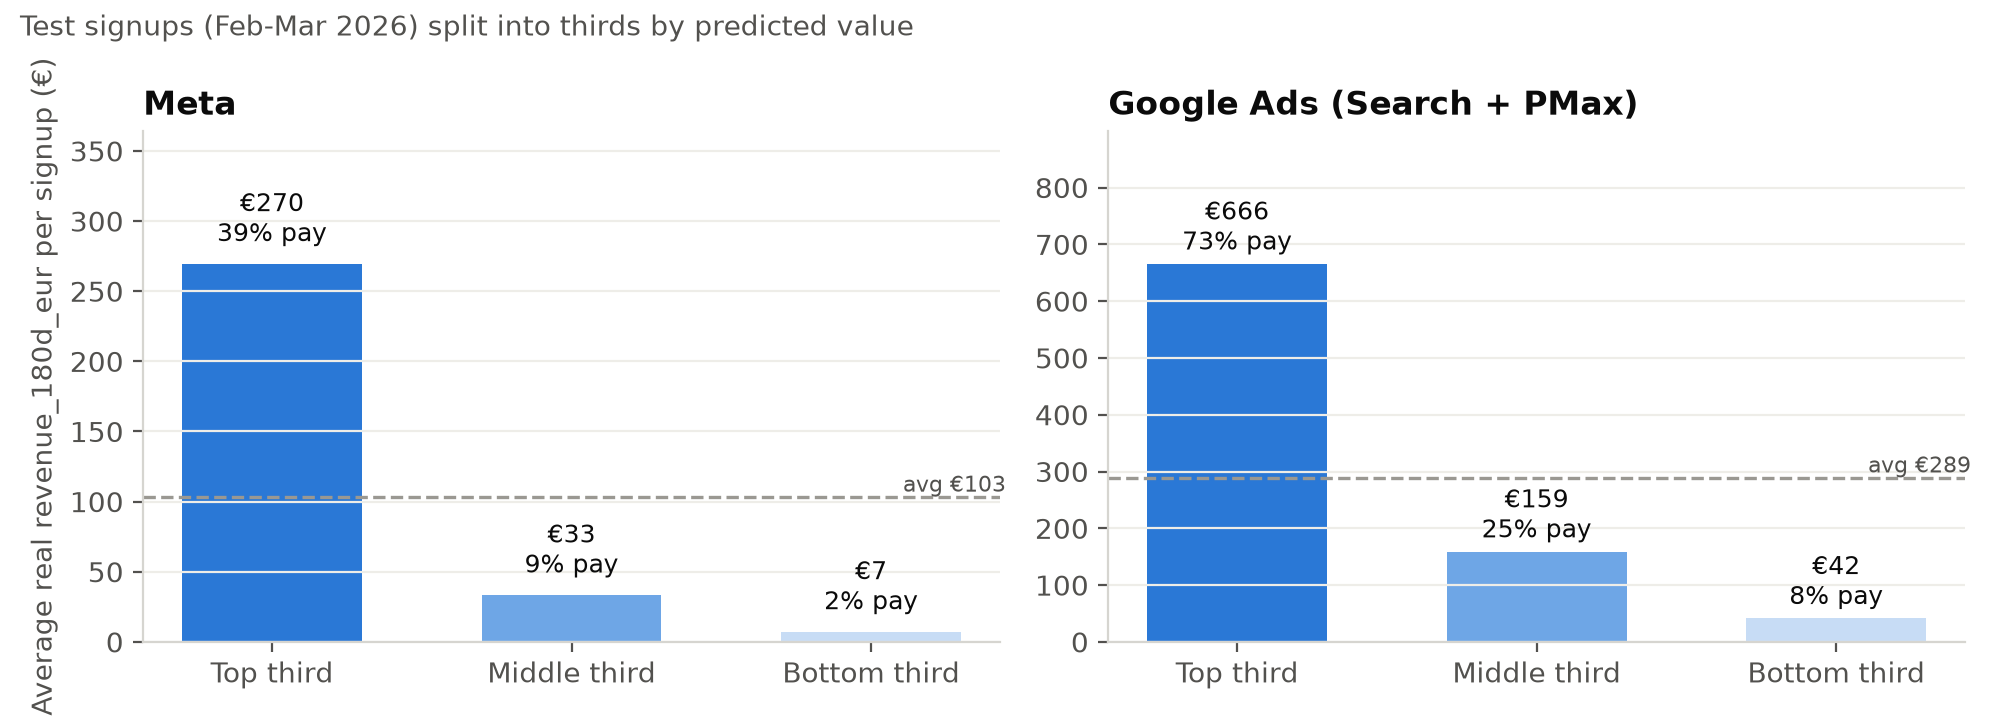

In [12]:
for platform in ["meta","google"]:
    t = ev.tertile_table(scores[platform], y_paid[test_mask[platform]], y_rev[test_mask[platform]])
    print(f"--- {platform} ---")
    display(t.rename(columns={"leads": "signups", "paid_rate": "paid within 30d", "revenue_per_lead": "real revenue per signup", "predicted_per_lead": "model's predicted value"})
            .style.format({"paid within 30d": "{:.0%}", "real revenue per signup": "€{:.0f}", "model's predicted value": "€{:.0f}"}))
display(Image("../outputs/figures/tertiles.png", width=900))

The same thing from Meta's point of view: today every signup is sent as equal; with the model each signup carries its own value. The boxes show what the signups in each third look like and what they really brought.

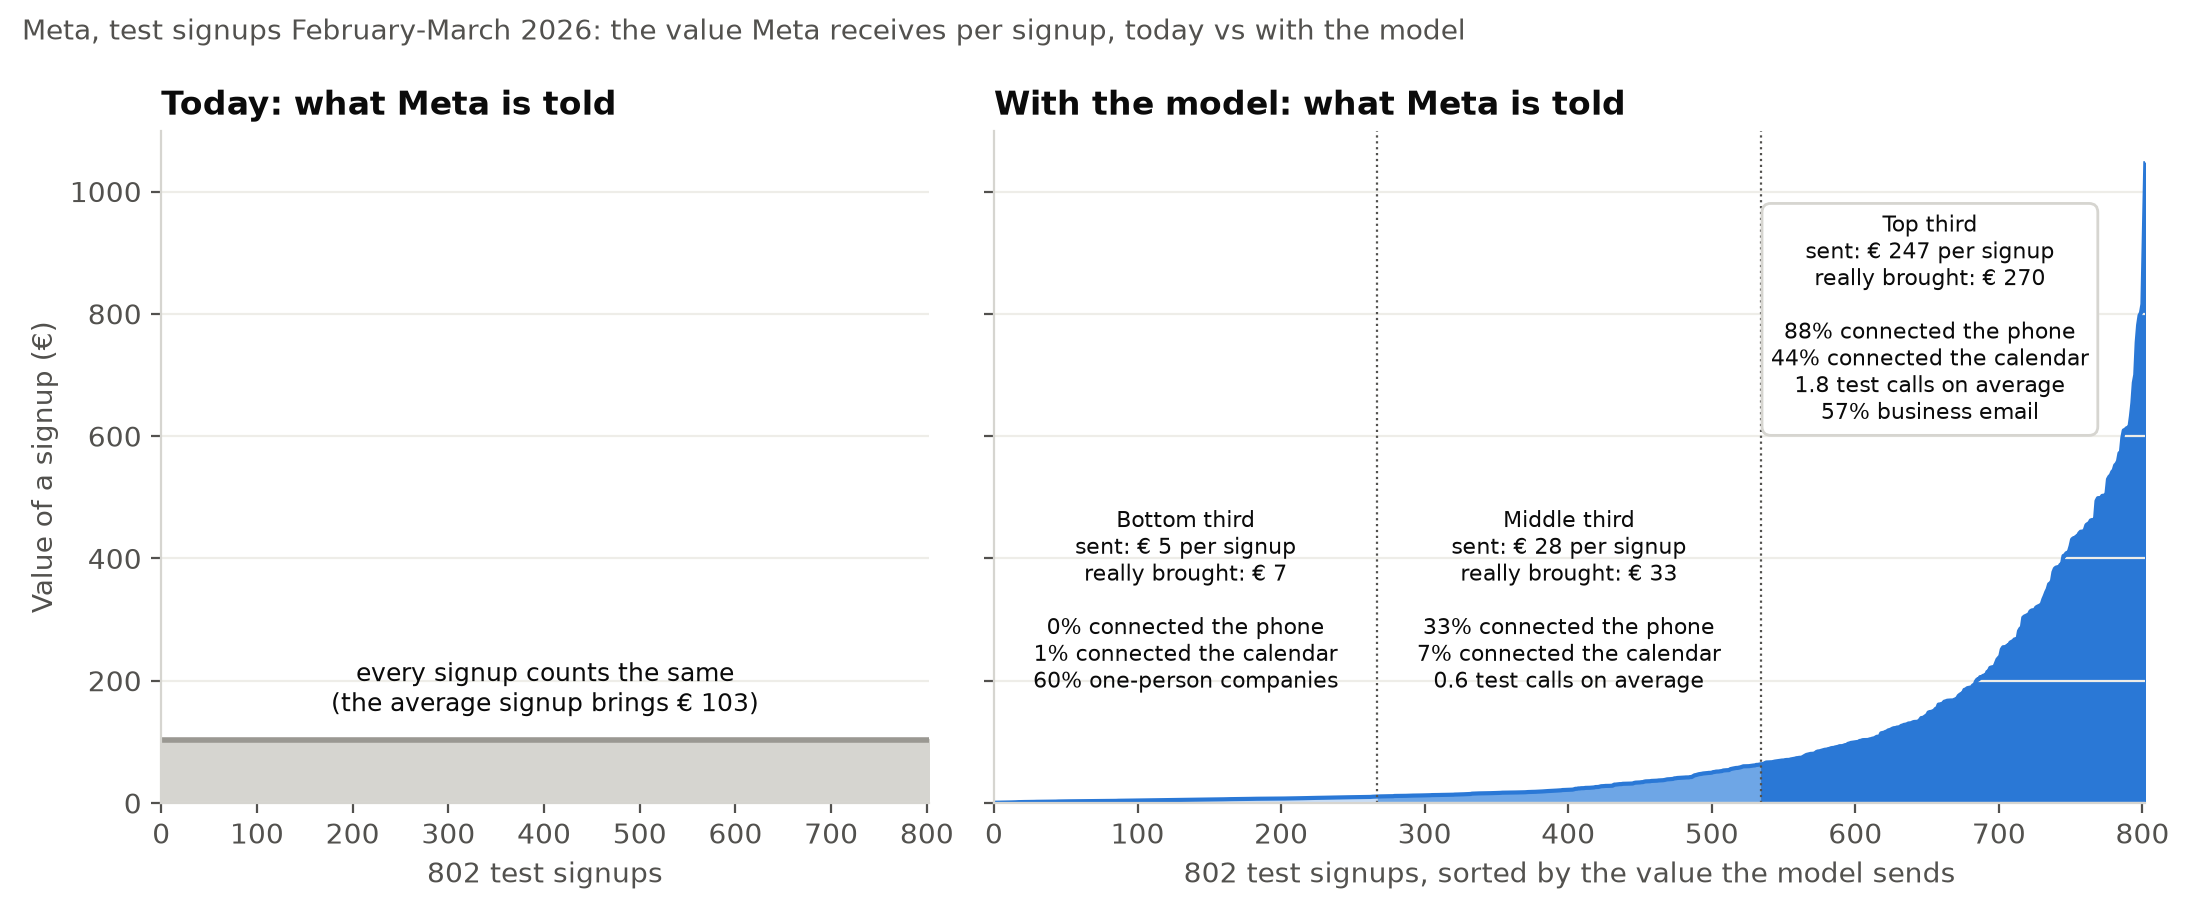

In [13]:
display(Image("../outputs/figures/value_distribution_meta.png", width=1000))

Google Ads, same chart:

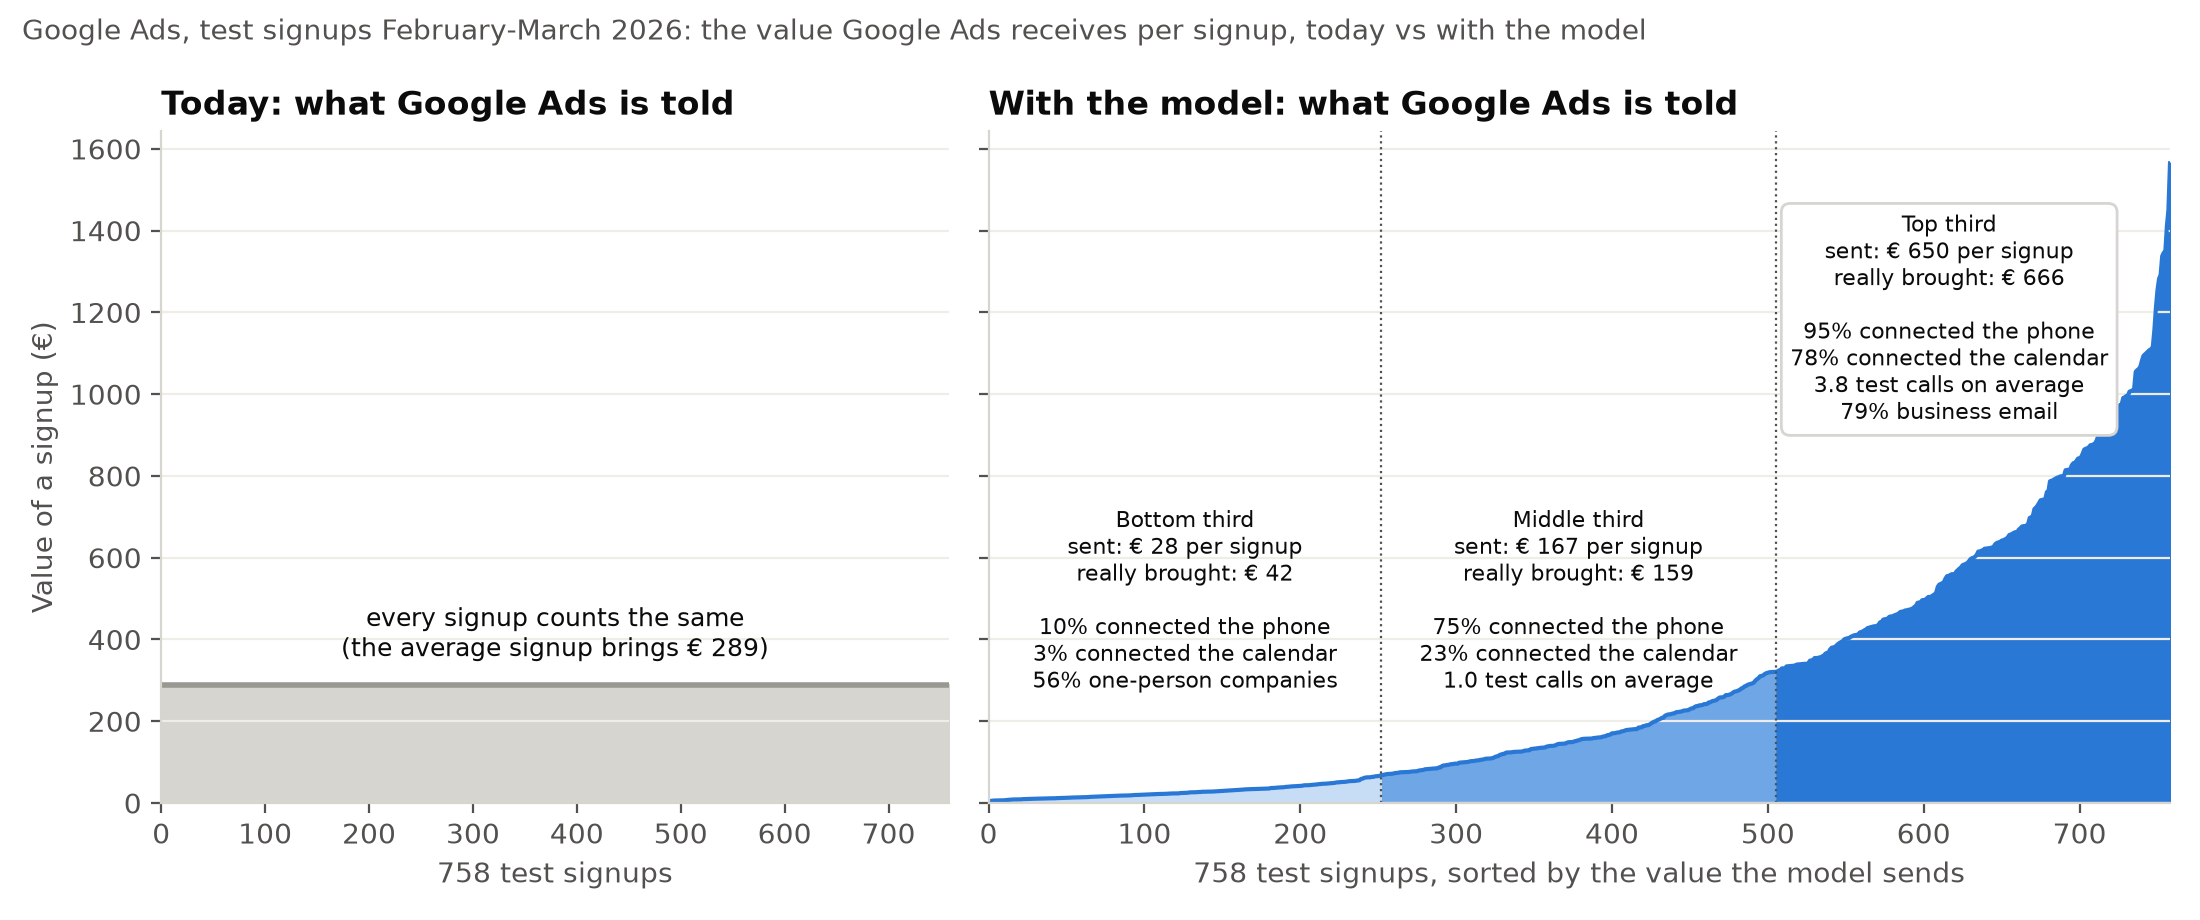

In [14]:
display(Image("../outputs/figures/value_distribution_google.png", width=1000))

### 4c. Can the euro number be trusted? (calibration)

The platforms will treat our value as money and compute return on ad spend from it. So when the model says "€ 300", those signups should really bring about € 300 on average. We split the test signups into five groups by predicted value and compare the average prediction with the average real revenue.

--- meta ---


,signups,model said (avg €),really brought (avg €)
bin,,,
0,161,€3,€8
1,160,€9,€16
2,160,€25,€36
3,160,€80,€63
4,161,€348,€392


--- google ---


,signups,model said (avg €),really brought (avg €)
bin,,,
0,152,€17,€31
1,151,€57,€61
2,152,€158,€168
3,151,€366,€351
4,152,€810,€833


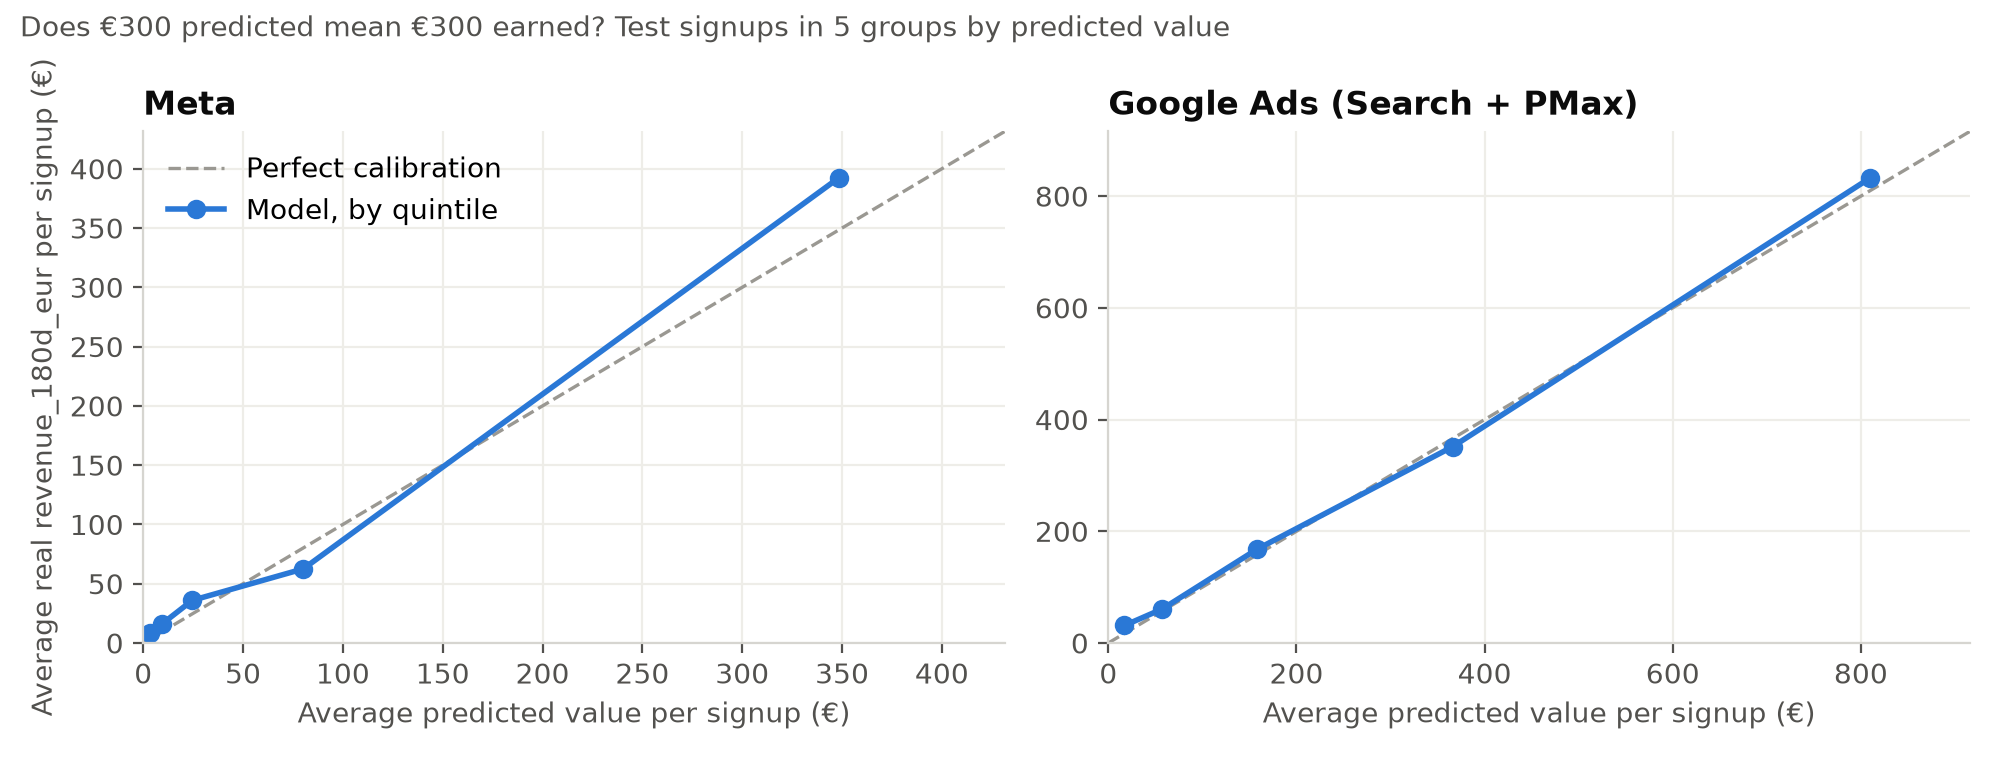

In [15]:
for platform in ["meta","google"]:
    print(f"--- {platform} ---")
    display(ev.calibration_table(scores[platform], y_rev[test_mask[platform]]).rename(columns={"leads": "signups", "predicted": "model said (avg €)", "actual": "really brought (avg €)"}).style.format({"model said (avg €)": "€{:.0f}", "really brought (avg €)": "€{:.0f}"}))
display(Image("../outputs/figures/calibration.png", width=900))

Both models are close to the diagonal; on average the Meta model is about 10% conservative (€ 93 predicted vs € 103 real), Google within 3%.

### 4d. The weights: what the models actually learned

Four tables: for each platform, step 1 ("will they pay?") and step 2 ("if they pay, how much?"). Positive = pushes the number up. Weights are comparable within a table because every feature was put on the same scale before training.

In [16]:
w = pd.DataFrame({
    ("Meta", "step 1: will pay?"): models["meta"].coefficients(),
    ("Meta", "step 2: € if pays"): models["meta"].coefficients_stage2(),
    ("Google Ads", "step 1: will pay?"): models["google"].coefficients(),
    ("Google Ads", "step 2: € if pays"): models["google"].coefficients_stage2(),
})
w = w[~w.index.str.startswith("channel_")].sort_values(("Meta", "step 1: will pay?"), ascending=False)
w.style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-1, vmax=1, subset=[("Meta","step 1: will pay?"),("Google Ads","step 1: will pay?")])

Reading the table: what people **do** in the first three days (phone, test calls, calendar) matters most; what they **are** (industry, company size) matters too but less. A one-person automotive business on mobile that did nothing is the lowest-value profile on Meta; a medical or property-management company with 6–20 staff that connected everything is the highest.

## 5. Other checks we made on the way

**One model for all channels instead of two?** We trained a model on all 6,000 signups and then asked it to score only the Meta test signups (and only the Google ones). Ranking quality is the same. But without the channel as an input, the all-channel model gets the euro level wrong: it predicts € 124 per Meta signup where the truth is € 103 (+20%), and € 254 for Google where the truth is € 289. That is because a Meta signup with the same behaviour pays less than a Google signup (table below). Separate models avoid this without extra assumptions.

In [17]:
seg = np.select([df.calendar_connected_72h.eq(1), df.phone_connected_24h.eq(1)], ["3 calendar connected by 72h", "2 phone connected, no calendar"], "1 nothing in the first 24h")
print("Share who paid within 30 days, by what they did and where they came from:")
pd.pivot_table(df.assign(behaviour=seg), index="behaviour", columns="channel", values="converted_paid_30d", aggfunc="mean").style.format("{:.0%}")

Share who paid within 30 days, by what they did and where they came from:


channel,google_pmax,google_search,meta,organic,referral
behaviour,,,,,
1 nothing in the first 24h,7%,11%,4%,8%,5%
"2 phone connected, no calendar",27%,31%,21%,27%,30%
3 calendar connected by 72h,53%,67%,46%,59%,62%


In [18]:
rows = []
for platform in ["meta","google"]:
    te = test_mask[platform]
    for label, inc in [("all channels, channel as input", True), ("all channels, no channel input", False)]:
        X = feature_frame(df, "72h", include_channel=inc)
        s = LeadValueModel().fit(X[train], y_paid[train], y_rev[train]).predict_value(X[te])
        r = ev.summary(s, y_paid[te], y_rev[te]); rows.append({"scored platform": platform, "model": label, "revenue in top 30%": r["revenue_top30_share"], "model said (avg €)": r["predicted_mean"], "really (avg €)": r["actual_mean"]})
    r = ev.summary(scores[platform], y_paid[te], y_rev[te]); rows.append({"scored platform": platform, "model": "separate per platform (chosen)", "revenue in top 30%": r["revenue_top30_share"], "model said (avg €)": r["predicted_mean"], "really (avg €)": r["actual_mean"]})
pd.DataFrame(rows).set_index(["scored platform","model"]).style.format({"revenue in top 30%": "{:.0%}", "model said (avg €)": "€{:.0f}", "really (avg €)": "€{:.0f}"})

**Google Search and PMax: one model or two?** Both are campaign types inside the same Google Ads account and bid on the same conversion action, so one model is simpler. We checked anyway: a PMax-only model has just 545 training signups and is not better than the joint model, which already knows whether a signup came from Search or PMax.

In [19]:
pd.DataFrame(R["tables"]["search_vs_pmax"]).set_index(["channel","model"])[["n_train","revenue_top30_share","predicted_mean","actual_mean"]].rename(columns={"n_train": "training signups", "revenue_top30_share": "revenue in top 30%", "predicted_mean": "model said (avg €)", "actual_mean": "really (avg €)"}).style.format({"revenue in top 30%": "{:.0%}", "model said (avg €)": "€{:.0f}", "really (avg €)": "€{:.0f}"})

**A fancier algorithm?** We also tried gradient boosting (many small decision trees) and a one-step variant (chance of paying × one average revenue for everybody). Neither beats the two-step logistic model on 1,500-1,800 training signups, and the logistic model is the only one whose weights can be printed and sanity-checked by a marketer. So we keep it.

In [20]:
rows = []
for platform in ["meta","google"]:
    tr, te = train & channel_mask(df, platform), test_mask[platform]
    for label, kw in [("two-step logistic + ridge (chosen)", {}), ("one-step: P(pay) × average payer revenue", dict(stage2="const")), ("gradient boosting, two steps", dict(stage1="gbm", stage2="gbm"))]:
        s = LeadValueModel(**kw).fit(X72[tr], y_paid[tr], y_rev[tr]).predict_value(X72[te])
        r = ev.summary(s, y_paid[te], y_rev[te]); rows.append({"platform": platform, "model": label, "revenue in top 30%": r["revenue_top30_share"], "model said (avg €)": r["predicted_mean"], "really (avg €)": r["actual_mean"]})
pd.DataFrame(rows).set_index(["platform","model"]).style.format({"revenue in top 30%": "{:.0%}", "model said (avg €)": "€{:.0f}", "really (avg €)": "€{:.0f}"})

## 6. Decisions

| Question from the task | Decision |
|---|---|
| Model | Two models (Meta; Google Ads = Search + PMax). Each: logistic regression "will they pay?" × ridge regression "how much if they pay?" → expected 180-day revenue in EUR. Organic and referral are not used. |
| When to score | 72 hours after signup |
| Features used | country, industry, company_size, device, business_email, signup_hour, signup_date (weekday), phone_connected_24h, assistant_configured_24h, test_calls_72h, calendar_connected_72h, plus our own paid_by_72h and plan_by_72h |
| Features left out | `minutes_used_7d` (after 7 days), `onboarding_call_booked` (no timestamp), `converted_paid_30d` and `revenue_180d_eur` (after 30 / 180 days, the answers), `plan_selected` and `days_to_first_payment` (filled in only after a payment) |
| Validation | trained on Oct-Jan 2026, tested on Feb-Mar 2026; compared with "every signup the same" |
| Result | the 30% of signups with the highest predicted value bring 85% (Meta) / 74% (Google) of revenue vs 30% today; predicted euros within 10% of real euros |
| In production | the formula is applied every day to signups that turned 72h old; it is re-trained once a month on the latest signups whose outcomes are known, and replaced only if it beats the current one on the last two months |

The scored test signups are saved in `outputs/scored_test_set.csv` (one row per signup: predicted value, real outcome).